# 1. Análisis exploratorio de la serie BTCUSDT

Analizamos el precio de cierre diario del par BTCUSDT en Binance entre el 1 de enero de 2018 y el 31 de diciembre de 2025. El objetivo es caracterizar la serie antes de modelarla: nivel y tendencia, distribución de los retornos, volatilidad, estacionariedad y dependencia temporal. En la sección 1.1 definimos el tramo que reservamos como hold-out temporal y en la 1.8 resumimos las implicaciones para el modelado.

In [9]:
# Rutas: en Colab se usa la carpeta de Drive; en el repositorio, la raíz del proyecto.
import os, glob, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

DRIVE = Path("/content/drive/MyDrive/tarea2_series")
if DRIVE.exists():
    BASE, FIGS = DRIVE, DRIVE / "figs"
else:
    BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    FIGS = BASE / "notebooks" / "figs"
RESULTS = BASE / os.environ.get("T2_RESULTS_DIR", "results")
FIGS.mkdir(parents=True, exist_ok=True)

LAGS, HS, ESTRATEGIAS = [7, 14, 21, 28], [7, 14, 21, 28], ["gk", "fc", "kf"]
NOMBRE = {"gk": "Group K-Fold", "fc": "Forward Chaining", "kf": "K-Fold"}
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]          # orden categorico fijo
COL_EST = dict(zip(ESTRATEGIAS, COL))
COL_LAG = dict(zip(LAGS, COL))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
                     "axes.prop_cycle": plt.cycler(color=COL), "lines.linewidth": 1.6,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.labelsize": 10})

df = pd.read_csv(BASE / "data" / "btc_1d.csv", parse_dates=["date"])
y = df["close"].to_numpy(float)
DATES = df["date"].to_numpy()
N_HOLD = max(int(len(y) * 0.10), 56)
N_CV = len(y) - N_HOLD


def guardar(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", bbox_inches="tight", dpi=150)

## 1.1 Datos

In [10]:
print(f"Observaciones: {len(df)} días | desde {df.date.min().date()} hasta {df.date.max().date()}")
print("Días faltantes:", int((df.date.diff().dt.days > 1).sum()), "| valores nulos:", int(df.isna().sum().sum()))
print(f"Hold-out temporal: últimos {N_HOLD} días ({df.date.iloc[N_CV].date()} a {df.date.iloc[-1].date()})")
df.describe().T.round(2)

Observaciones: 2922 días | desde 2018-01-01 hasta 2025-12-31
Días faltantes: 0 | valores nulos: 0
Hold-out temporal: últimos 292 días (2025-03-15 a 2025-12-31)


,count,mean,min,25%,50%,75%,max,std
date,2922,2021-12-31 12:00:00,2018-01-01 00:00:00,2020-01-01 06:00:00,2021-12-31 12:00:00,2023-12-31 18:00:00,2025-12-31 00:00:00,NaN
open,2922.0,37231.440992,3211.71,9448.6975,27281.415,57350.655,124658.54,32206.842402
high,2922.0,38017.42871,3276.5,9677.3775,27817.425,58531.075,126199.63,32733.299783
low,2922.0,36387.343569,3156.26,9211.455,26816.68,55718.2775,123084.0,31647.909842
close,2922.0,37256.764904,3211.72,9448.7,27342.495,57363.14,124658.54,32217.426527
volume,2922.0,65226.063903,1521.537318,26410.395921,41308.242356,68389.152521,760705.362783,77569.307502


La serie tiene 2922 observaciones diarias, sin días faltantes ni valores nulos, porque Binance opera de forma continua. El cierre va de 3211.72 USD a 124 658.54 USD, un factor cercano a 39 entre el mínimo y el máximo. La media (37 256.76 USD) supera a la mediana (27 342.50 USD) y la desviación estándar (32 217.43 USD) es del mismo orden que la media: la distribución de niveles es asimétrica a la derecha y está dominada por los años de precios altos. Esta amplitud de escala es la razón por la que modelamos el logaritmo del precio y no el precio en USD.

Reservamos como hold-out los últimos 292 días (15 de marzo a 31 de diciembre de 2025). La cifra cumple las dos condiciones del enunciado: es el 10 % de la serie y supera 2H = 56 días para el horizonte más largo (H = 28). Ningún dato del hold-out interviene en la búsqueda de arquitecturas ni en la selección de modelos.

## 1.2 Nivel de precio y tendencia

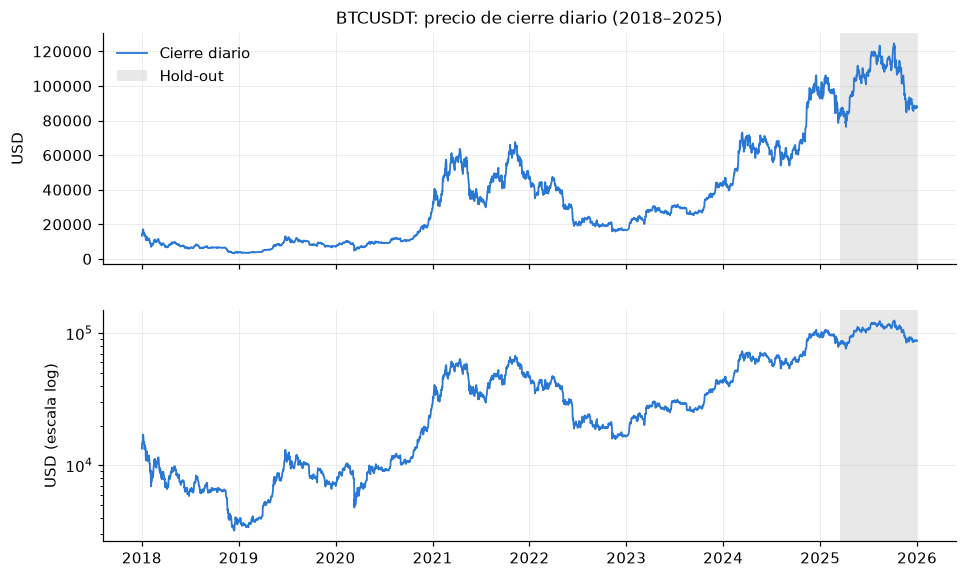

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for a, logy in zip(ax, (False, True)):
    a.plot(df.date, df.close, color=COL[0], lw=1.2, label="Cierre diario")
    a.axvspan(df.date.iloc[N_CV], df.date.iloc[-1], color="0.85", alpha=0.6, lw=0, label="Hold-out")
    a.set_ylabel("USD (escala log)" if logy else "USD")
    if logy:
        a.set_yscale("log")
ax[0].set_title("BTCUSDT: precio de cierre diario (2018–2025)")
ax[0].legend(loc="upper left")
guardar(fig, "eda_precio"); plt.show()

La figura en escala lineal muestra cuatro regímenes: la caída de 2018, el ciclo alcista de finales de 2020 a 2021, el mercado bajista de 2022 y la recuperación de 2023 a 2025. En escala logarítmica las oscilaciones de 2018–2019 y las de 2024–2025 tienen amplitudes comparables, lo que indica que las variaciones del precio son aproximadamente proporcionales a su nivel. Esto respalda el uso de log(precio) como variable modelada.

El hecho más relevante para la evaluación es que el máximo de toda la serie cae dentro del hold-out y supera el máximo alcanzado antes de marzo de 2025. Como escalamos cada fold con la media y la desviación estándar de su tramo de entrenamiento, en el hold-out la red recibe entradas fuera del rango que vio al entrenar y debe extrapolar. Un MLP con activaciones ReLU extrapola de forma lineal por tramos, sin garantía de seguir la dinámica real. Por eso comparamos siempre contra un baseline ingenuo (repetir el último valor observado), que no depende del rango de entrenamiento.

## 1.3 Retornos logarítmicos

media 0.00064 | desv. estándar 0.0348 | asimetría -1.15 | curtosis en exceso 17.80
Jarque-Bera p = 0.00e+00


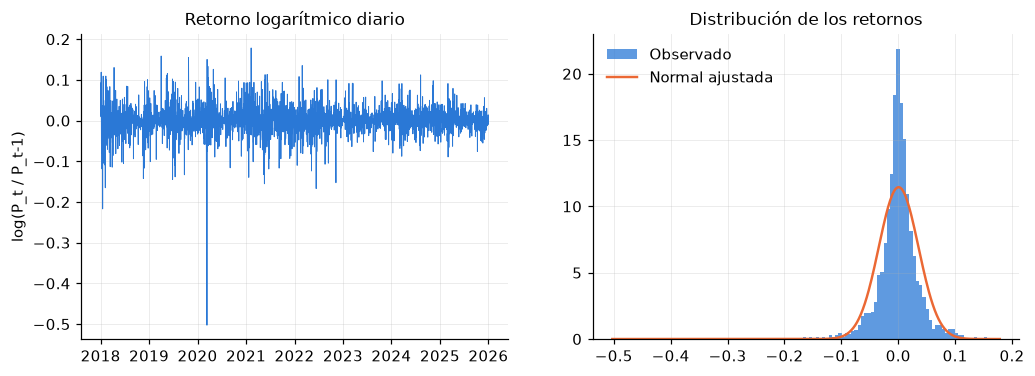

In [12]:
r = np.diff(np.log(y))
from scipy import stats
print(f"media {r.mean():.5f} | desv. estándar {r.std():.4f} | asimetría {stats.skew(r):.2f} | "
      f"curtosis en exceso {stats.kurtosis(r):.2f}")
print(f"Jarque-Bera p = {stats.jarque_bera(r).pvalue:.2e}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(df.date[1:], r, color=COL[0], lw=0.6)
ax[0].set_title("Retorno logarítmico diario"); ax[0].set_ylabel("log(P_t / P_t-1)")
ax[1].hist(r, bins=120, density=True, color=COL[0], alpha=0.75, label="Observado")
xx = np.linspace(r.min(), r.max(), 400)
ax[1].plot(xx, stats.norm.pdf(xx, r.mean(), r.std()), color=COL[1], label="Normal ajustada")
ax[1].set_title("Distribución de los retornos"); ax[1].legend()
guardar(fig, "eda_retornos"); plt.show()

El retorno logarítmico medio es 0.00064 por día, que equivale a unos 0.23 por año en escala logarítmica, y su desviación estándar diaria es 0.0348. La desviación es unas 54 veces la media: en un horizonte de días, el ruido domina por completo a la deriva. La asimetría (−1.15) indica caídas extremas más grandes que las subidas extremas, y la curtosis en exceso (17.80, frente a 0 en una normal) indica colas mucho más pesadas que las gaussianas. El histograma lo confirma: más masa en el centro y en las colas que la normal ajustada. La prueba de Jarque-Bera rechaza la normalidad (p menor que la precisión numérica que reporta la librería).

El retorno más extremo, cercano a −0.5 según la figura, corresponde a marzo de 2020, es decir, una caída de alrededor de 40 % en un día. Para el modelado esto tiene dos consecuencias. La pérdida MSE penaliza con fuerza esos pocos eventos y puede sesgar el ajuste hacia ellos. Además, no debemos esperar residuos normales, así que reportamos MAE junto a RMSE, porque el MAE es menos sensible a los valores extremos.

## 1.4 Volatilidad

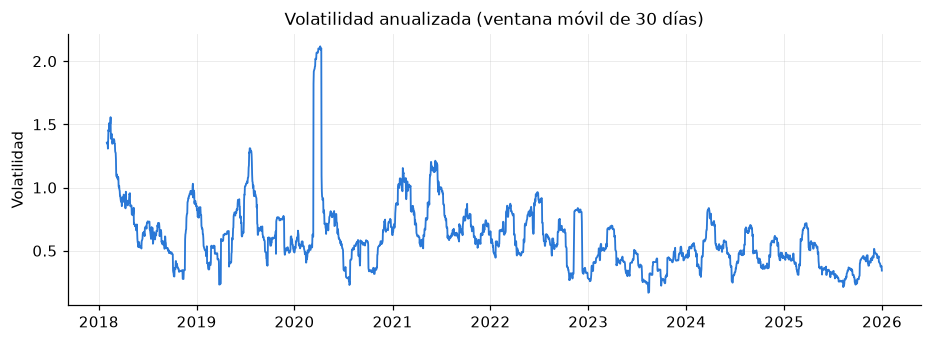

date
2018    0.750
2019    0.663
2020    0.680
2021    0.788
2022    0.631
2023    0.416
2024    0.510
2025    0.409


In [13]:
vol = pd.Series(r, index=df.date[1:]).rolling(30).std() * np.sqrt(365)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(vol.index, vol, color=COL[0], lw=1.2)
ax.set_title("Volatilidad anualizada (ventana móvil de 30 días)"); ax.set_ylabel("Volatilidad")
guardar(fig, "eda_volatilidad"); plt.show()
print(vol.groupby(vol.index.year).mean().round(3).to_string())

La volatilidad no es constante. La media anual de la volatilidad anualizada se mantiene entre 0.63 y 0.79 de 2018 a 2022 y baja a 0.416 en 2023, 0.510 en 2024 y 0.409 en 2025. El pico de la serie, por encima de 2.0, coincide con marzo de 2020. Este cambio de régimen tiene dos efectos sobre la evaluación. Primero, el hold-out (2025) cae en el periodo de menor volatilidad de la muestra, lo que favorece errores porcentuales bajos en ese tramo; no sería correcto extrapolar ese desempeño a periodos más volátiles. Segundo, como el error absoluto en USD crece con el nivel del precio, las métricas en USD (MAE, RMSE) no son comparables entre épocas distintas de la serie, y por eso usamos el MAPE para comparar entre configuraciones y folds.

## 1.5 Estacionariedad (ADF y KPSS)

In [14]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.simplefilter("ignore", InterpolationWarning)
filas = []
for nombre, s in (("precio", y), ("log(precio)", np.log(y)), ("retorno log", r)):
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    filas.append(dict(serie=nombre, ADF_pvalor=adf_p, KPSS_pvalor=kpss_p))
tabla_est = pd.DataFrame(filas).round(4)
tabla_est.to_csv(RESULTS / "eda_estacionariedad.csv", index=False)
tabla_est

,serie,ADF_pvalor,KPSS_pvalor
0,precio,0.8279,0.01
1,log(precio),0.8853,0.01
2,retorno log,0.0000,0.10


ADF tiene como hipótesis nula una raíz unitaria (no estacionaria); KPSS tiene como hipótesis nula la estacionariedad. KPSS reporta p-valores acotados al intervalo [0.01, 0.10].

Para el precio y para log(precio), ADF no rechaza la raíz unitaria (p = 0.83 y 0.89) y KPSS rechaza la estacionariedad (p ≤ 0.01; el valor real es menor, porque el estadístico cae fuera de la tabla). Las dos pruebas apuntan en la misma dirección: el nivel no es estacionario. Para el retorno logarítmico ocurre lo contrario: ADF rechaza la raíz unitaria (p < 0.0001) y KPSS no rechaza la estacionariedad (p ≥ 0.10). La serie se comporta como integrada de orden 1: su primera diferencia es estacionaria en media.

El enunciado pide predecir el nivel del precio, y modelamos log(precio) escalado con la media y la desviación del tramo de entrenamiento de cada fold. Este escalado no vuelve estacionaria la serie: un fold cuyo tramo de validación está en otro nivel de precio queda desplazado respecto a lo que la red vio al entrenar. Lo declaramos como limitación del diseño. La alternativa natural, modelar retornos y reconstruir el nivel, queda como trabajo futuro.

## 1.6 Dependencia temporal (ACF y PACF)

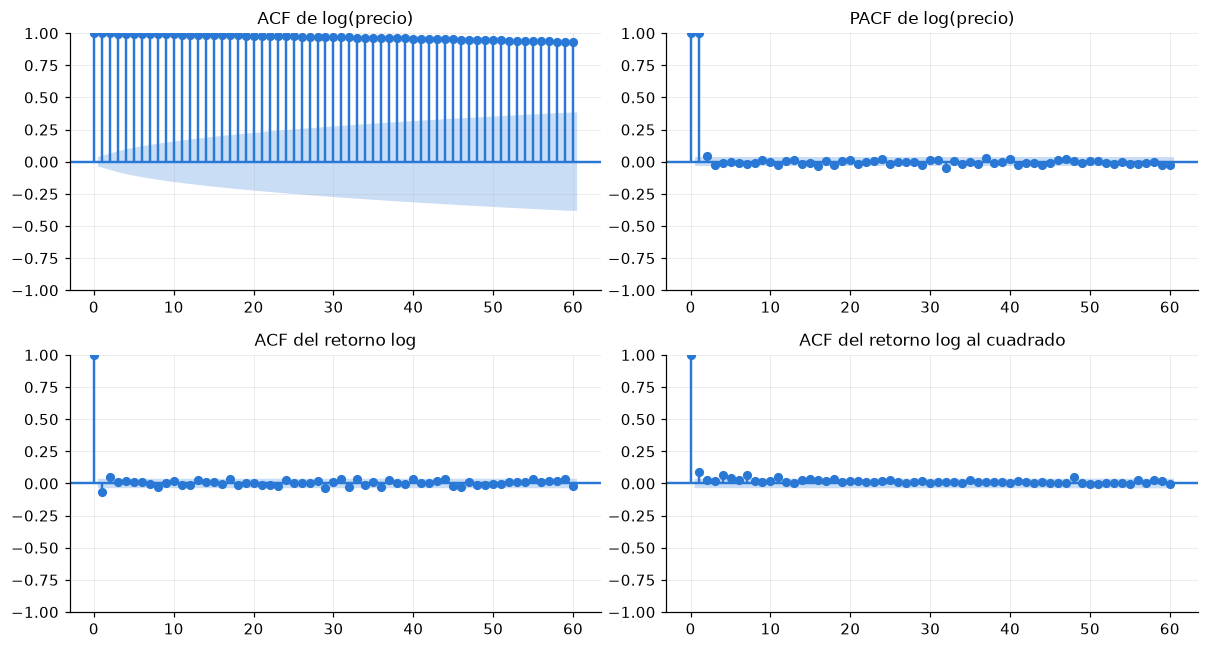

In [15]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
plot_acf(np.log(y), lags=60, ax=ax[0, 0], title="ACF de log(precio)")
plot_pacf(np.log(y), lags=60, ax=ax[0, 1], title="PACF de log(precio)", method="ywm")
plot_acf(r, lags=60, ax=ax[1, 0], title="ACF del retorno log")
plot_acf(r ** 2, lags=60, ax=ax[1, 1], title="ACF del retorno log al cuadrado")
fig.tight_layout(); guardar(fig, "eda_acf"); plt.show()

La ACF de log(precio) decae muy despacio (sigue por encima de 0.9 en el rezago 60) y la PACF tiene un único pico, cercano a 1, en el rezago 1. Es el patrón de una caminata aleatoria: casi toda la información sobre el precio de mañana está en el precio de hoy. La ACF del retorno muestra una autocorrelación pequeña y negativa en el rezago 1 (en torno a −0.06 según la figura); los demás rezagos quedan, en su mayoría, dentro o cerca de la banda de confianza. Hay, por tanto, poca dependencia lineal aprovechable en los rezagos 7 a 28 que usa el modelo.

La ACF del retorno al cuadrado es positiva en varios rezagos (cerca de 0.09 en el rezago 1), lo que indica agrupamiento de volatilidad: los días de movimientos grandes tienden a seguir a otros días de movimientos grandes. Esta dependencia afecta la magnitud de los cambios, no su dirección, y por eso un modelo de pronóstico puntual difícilmente la aprovecha. Una explicación coherente de que los valores sean bajos es el peso del retorno de marzo de 2020 en la varianza muestral; no lo verificamos aquí.

Con estos resultados, esperamos que el MLP no supere con amplitud al baseline ingenuo y que su ventaja, si existe, sea pequeña. Que la red se acerque a la persistencia ya sería un resultado consistente con la estructura de la serie. La prueba BDS sobre los residuos (notebook 4) sirve para comprobar si queda dependencia no lineal sin explicar.

## 1.7 Volumen negociado

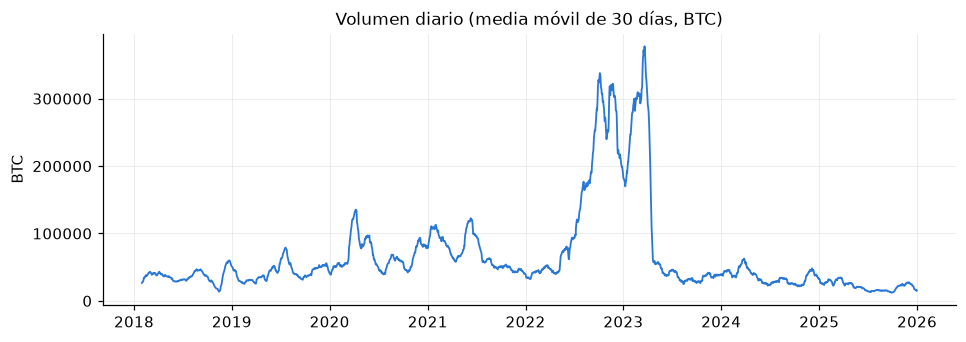

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(df.date, df.volume.rolling(30).mean(), color=COL[0], lw=1.2)
ax.set_title("Volumen diario (media móvil de 30 días, BTC)"); ax.set_ylabel("BTC")
guardar(fig, "eda_volumen"); plt.show()

El volumen promedio se mantiene por debajo de unos 130 000 BTC diarios hasta mediados de 2022, se multiplica entre mediados de 2022 y marzo de 2023 y cae de forma abrupta a finales de marzo de 2023. El intervalo coincide con la promoción de comisión cero de Binance para 13 pares de BTC, incluido BTC-USDT, que estuvo vigente del 8 de julio de 2022 al 22 de marzo de 2023 (Kaiko, 2023). El salto refleja, por tanto, un cambio en las condiciones de la plataforma y no en la actividad del mercado en su conjunto. Como el modelo es univariado y solo usa el precio de cierre, el volumen no entra como variable; lo reportamos para dejar constancia de que no es una serie homogénea en el tiempo.

## 1.8 Implicaciones para el modelado

- **Variable modelada.** El precio abarca casi dos órdenes de magnitud y sus variaciones son proporcionales al nivel. Por eso modelamos log(precio) y evaluamos en USD tras invertir la transformación.
- **No estacionariedad.** El nivel es integrado de orden 1 (ADF y KPSS concuerdan). Escalar con la media y la desviación del entrenamiento no corrige este hecho, y lo declaramos como limitación.
- **Baseline obligatorio.** La ACF y la PACF del nivel tienen la forma de una caminata aleatoria, así que la persistencia (repetir el último valor) es un rival fuerte. Todo resultado del MLP se reporta frente a ese baseline y frente al `MLPRegressor`.
- **Hold-out exigente en nivel, favorable en volatilidad.** El hold-out contiene el máximo histórico, fuera del rango de entrenamiento, y a la vez el régimen de menor volatilidad de la muestra. Ambos hechos condicionan la lectura de sus métricas.
- **Métricas.** Colas pesadas y heterocedasticidad justifican reportar MAE y MAPE junto a RMSE y MSE, y revisar los residuos con la prueba BDS.

Referencia: Kaiko. (2023, 27 de marzo). *Binance volume plummets after end of zero-fee trading*. https://research.kaiko.com/insights/binance-volume-plummets-after-end-of-zero-fee-trading